# Clustering Methods Exercises

![Clustering.png](Assets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности


## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла - `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

In [1]:
from __future__ import print_function
import os
data_path = ['data']

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit

sns.set_style('whitegrid')
%matplotlib inline
RANDOM_STATE = 42

## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме quality и color), являются непрерывными.

In [3]:
# Загрузка данных (файл лежит рядом с ноутбуком или в папке data)
path = 'Wine_Quality_Data.csv'
if not os.path.exists(path):
    path = os.path.join(*data_path, 'Wine_Quality_Data.csv')
data = pd.read_csv(path)

print(data.shape)
display(data.head())
display(data.dtypes)
print('Пропусков:', data.isna().sum().sum())

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

Пропусков: 0


In [4]:
# Типы признаков
float_columns = [c for c in data.columns if data[c].dtype == 'float64']
print('Непрерывные:', float_columns)
print('Категориальные (порядковые):', ['quality'])
print('Категориальные (бинарные/булевы):', ['color'])

# Количество записей по цветам и показателям качества
print(data['color'].value_counts(), '\n')
display(pd.crosstab(data['quality'], data['color'], margins=True))

Непрерывные: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Категориальные (порядковые): ['quality']
Категориальные (бинарные/булевы): ['color']
color
white    4898
red      1599
Name: count, dtype: int64 



color,red,white,All
quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5
All,1599,4898,6497


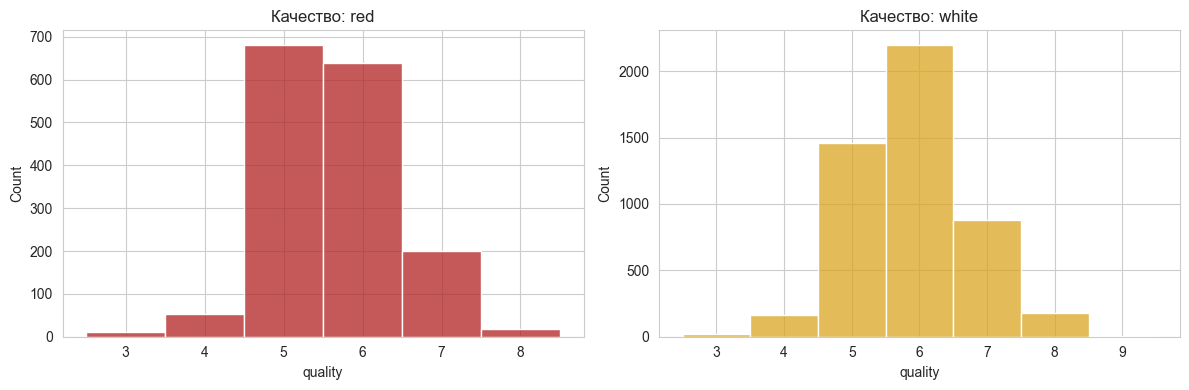

In [5]:
# Гистограммы показателя качества по цветам
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (color, c) in zip(axes, [('red', 'firebrick'), ('white', 'goldenrod')]):
    sns.histplot(data.loc[data['color'] == color, 'quality'], discrete=True, color=c, ax=ax)
    ax.set_title(f'Качество: {color}')
plt.tight_layout()
plt.show()

### Выводы (Вопрос 1)

- Данные: 6497 записей, пропусков нет. Белых вин 4898 (75%), красных 1599 (25%): классы несбалансированы.
- Все 11 химических признаков непрерывные (float64). `quality` - порядковая категориальная переменная (3-9), `color` - бинарная категориальная.
- Качество у обоих цветов сосредоточено в значениях 5-6 (у красных пик на 5, у белых на 6). Крайние оценки редки: оценка 9 только у 5 белых вин, оценка 3 всего у 30 вин.
- Для кластеризации берем 11 непрерывных признаков, что соответствует требованиям K-means.

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных - всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.


А также анализ значений асимметрии в преддверии преобразований.

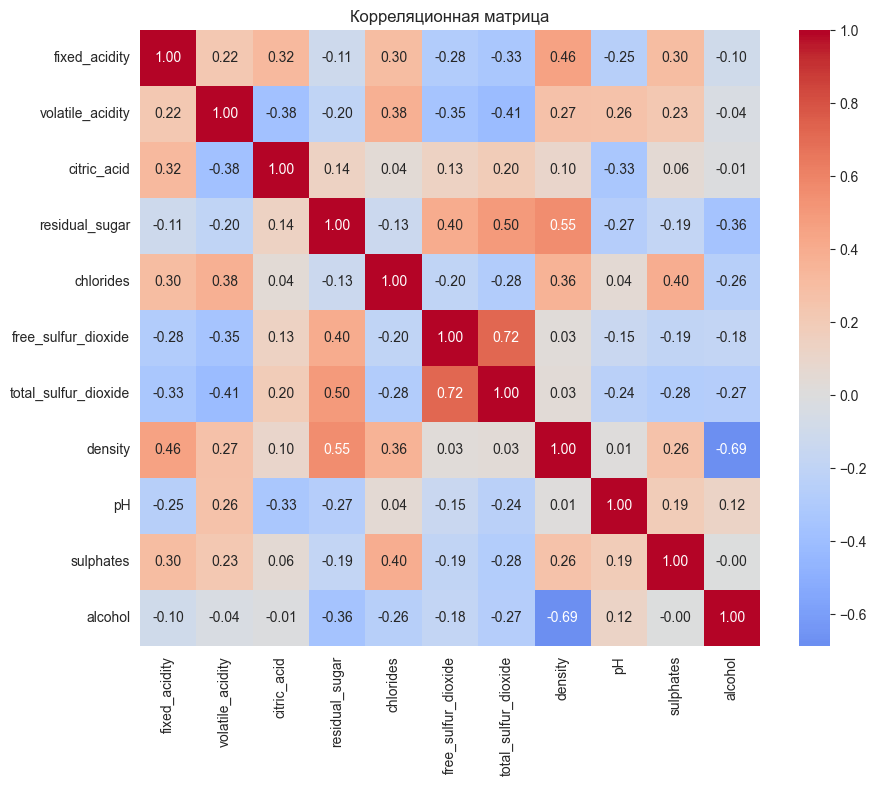

,skew
chlorides,5.399828
sulphates,1.797270
fixed_acidity,1.723290
volatile_acidity,1.495097
residual_sugar,1.435404
free_sulfur_dioxide,1.220066
alcohol,0.565718
density,0.503602
citric_acid,0.471731
pH,0.386839


In [6]:
# Корреляция и асимметрия
corr = data[float_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица')
plt.show()

skew = data[float_columns].skew().sort_values(ascending=False)
display(skew.to_frame('skew'))

In [7]:
# Преобразование: log1p для сильно асимметричных признаков (skew > 0.75), затем стандартизация
skewed_cols = skew[skew > 0.75].index.tolist()
print('Логарифмируем:', skewed_cols)

X = data[float_columns].copy()
X[skewed_cols] = np.log1p(X[skewed_cols])
print('\nАсимметрия после log1p:')
display(X.skew().sort_values(ascending=False).to_frame('skew'))

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=float_columns, index=X.index)
display(X_scaled.describe().loc[['mean', 'std']].round(3))

Логарифмируем: ['chlorides', 'sulphates', 'fixed_acidity', 'volatile_acidity', 'residual_sugar', 'free_sulfur_dioxide']

Асимметрия после log1p:


,skew
chlorides,4.484421
volatile_acidity,1.126873
sulphates,1.098588
fixed_acidity,0.976702
alcohol,0.565718
density,0.503602
citric_acid,0.471731
residual_sugar,0.414917
pH,0.386839
total_sulfur_dioxide,-0.001177


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
mean,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


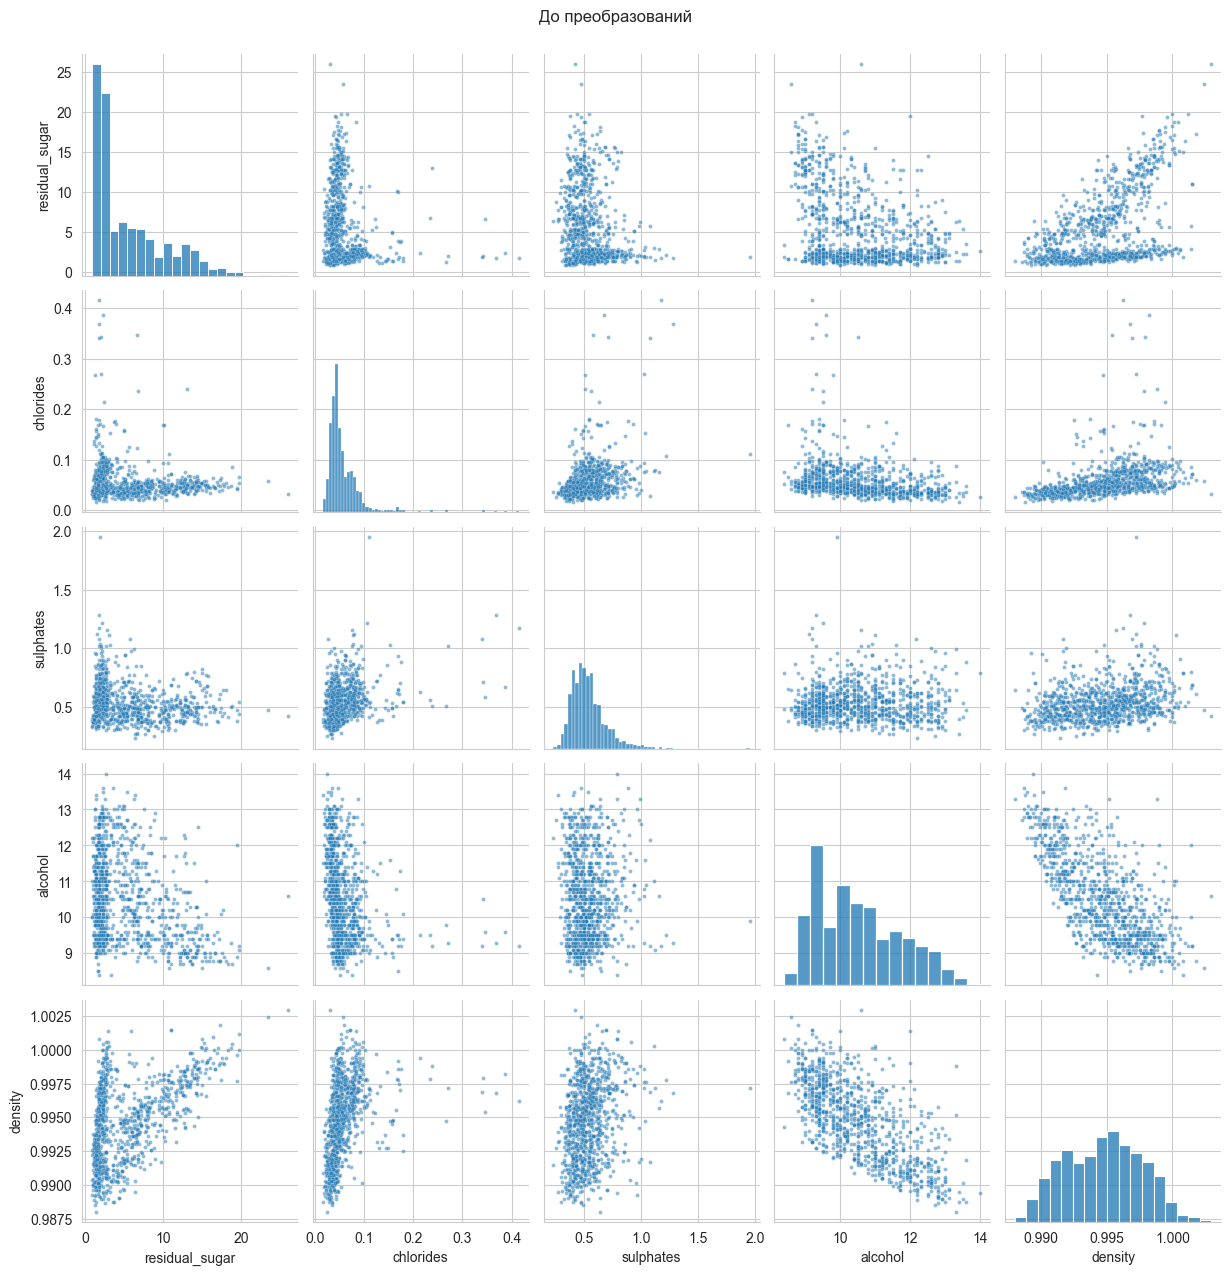

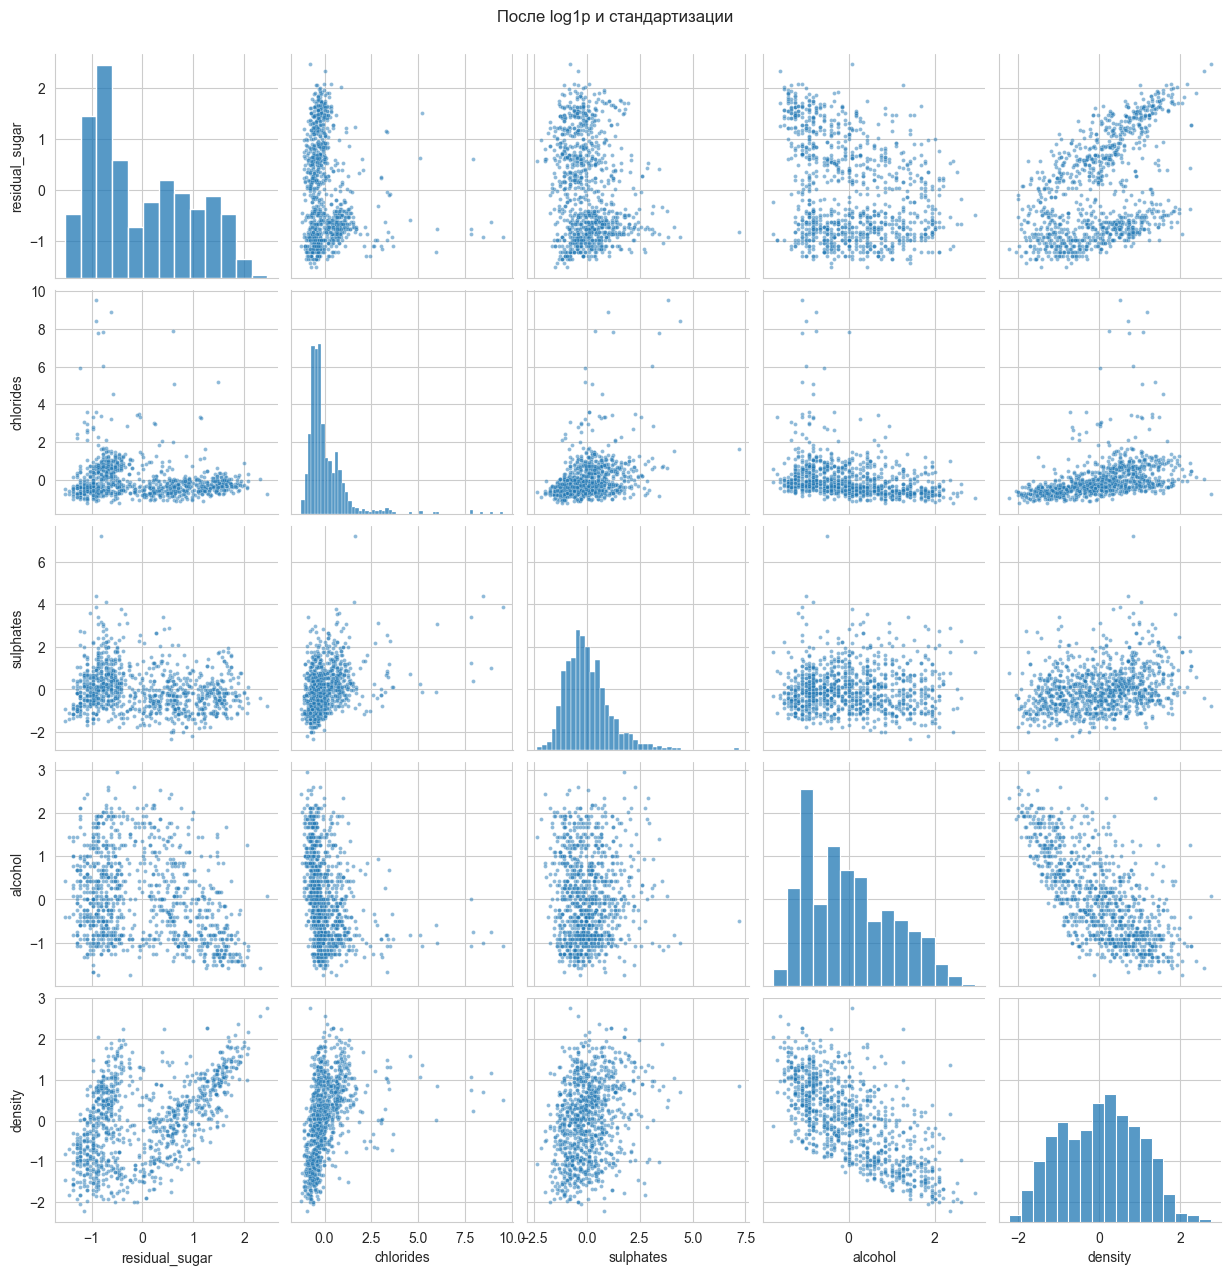

In [8]:
# Парные графики (на подвыборке для скорости): до и после преобразований
sample_idx = data.sample(1000, random_state=RANDOM_STATE).index
cols_pp = ['residual_sugar', 'chlorides', 'sulphates', 'alcohol', 'density']

g1 = sns.pairplot(data.loc[sample_idx, cols_pp], plot_kws={'s': 8, 'alpha': 0.5})
g1.fig.suptitle('До преобразований', y=1.02)
g2 = sns.pairplot(X_scaled.loc[sample_idx, cols_pp], plot_kws={'s': 8, 'alpha': 0.5})
g2.fig.suptitle('После log1p и стандартизации', y=1.02)
plt.show()

### Выводы (Вопрос 2)

- Самые сильные корреляции: `free_sulfur_dioxide` и `total_sulfur_dioxide` (0.72), `density` и `alcohol` (-0.69), `density` и `residual_sugar` (0.55). Признаки частично дублируют друг друга, но мультиколлинеарность умеренная, поэтому все признаки оставляем.
- Сильнее всего скошены `chlorides` (5.4), `sulphates`, `fixed_acidity`, `volatile_acidity`, `residual_sugar`, `free_sulfur_dioxide` (1.2-1.8). Для признаков с асимметрией больше 0.75 применили `log1p`; у большинства она заметно снизилась. У `chlorides` остался тяжелый правый хвост (4.5), а `free_sulfur_dioxide` после логарифмирования получил небольшую левую асимметрию (-0.72). Это допустимо, но выбросы в `chlorides` могут влиять на K-means.
- После `StandardScaler` у всех признаков среднее 0 и стандартное отклонение 1, то есть ни один признак не доминирует при расчете евклидова расстояния. Парные графики после преобразований выглядят более симметрично и компактно, чем до них.

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

In [9]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
data['kmeans'] = km2.fit_predict(X_scaled)

ct = pd.crosstab(data['color'], data['kmeans'])
display(ct)
display(pd.crosstab(data['color'], data['kmeans'], normalize='index').round(3))

# Доля вин, попавших в кластер, преобладающий для своего цвета
purity = ct.max(axis=1).sum() / ct.values.sum()
print(f'Чистота кластеров относительно цвета: {purity:.3f}')

kmeans,0,1
color,,
red,1576,23
white,87,4811


kmeans,0,1
color,,
red,0.986,0.014
white,0.018,0.982


Чистота кластеров относительно цвета: 0.983


### Выводы (Вопрос 3)

- K-means с двумя кластерами практически воспроизводит деление по цвету без использования этой информации: кластер 0 содержит 1576 из 1599 красных вин (98.6%), кластер 1 содержит 4811 из 4898 белых (98.2%). Общая чистота 98.3%.
- Значит, химический состав красных и белых вин существенно различается (в первую очередь сульфиты, сахар, кислотность). Ошибочно отнесено лишь около 1.7% вин. Номера кластеров произвольны.

## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

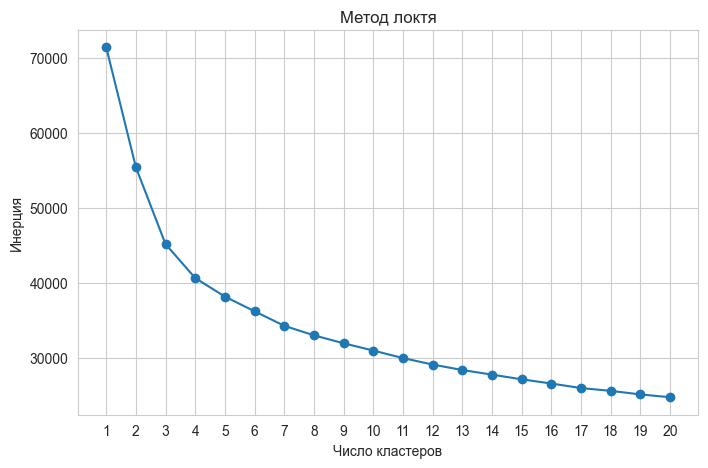

,inertia,drop_%
k,,
1,71467.000000,NaN
2,55455.981113,22.4
3,45199.883382,18.5
4,40674.070966,10.0
5,38203.472787,6.1
6,36241.873873,5.1
7,34307.726030,5.3
8,33037.467175,3.7
9,31976.433002,3.2


In [10]:
ks = range(1, 21)
inertias = []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(m.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(ks), inertias, 'o-')
plt.xticks(list(ks))
plt.xlabel('Число кластеров')
plt.ylabel('Инерция')
plt.title('Метод локтя')
plt.show()

pd.DataFrame({'k': list(ks), 'inertia': inertias, 'drop_%': pd.Series(inertias).pct_change().mul(-100).round(1)}).set_index('k')

### Выводы (Вопрос 4)

- Инерция монотонно убывает с ростом числа кластеров (с 71467 при k=1 до 24778 при k=20). Это ожидаемо, поэтому сама по себе она не показывает оптимум.
- Самое сильное падение происходит при переходе к k=2 (-22%) и k=3 (-18.5%), затем темп снижается до 10% при k=4 и около 5% при k=5-7, а дальше до 2-3% на шаг.
- Явного локтя нет. Разумный выбор: k=2 (соответствует делению по цвету) или k=3-4, где кривая начинает выходить на плато. Окончательный выбор лучше подтверждать другими метриками (например, силуэтом) и содержательной интерпретацией.

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

In [11]:
agg = AgglomerativeClustering(n_clusters=2, linkage='ward')
data['agglom'] = agg.fit_predict(X_scaled)

display(pd.crosstab(data['color'], data['agglom']))
display(pd.crosstab(data['color'], data['agglom'], normalize='index').round(3))

ct_a = pd.crosstab(data['color'], data['agglom'])
print(f'Чистота (агломеративная): {ct_a.max(axis=1).sum() / ct_a.values.sum():.3f}')

# Согласованность двух разбиений (номера кластеров произвольны)
display(pd.crosstab(data['kmeans'], data['agglom'], rownames=['kmeans'], colnames=['agglom']))

agglom,0,1
color,,
red,31,1568
white,4755,143


agglom,0,1
color,,
red,0.019,0.981
white,0.971,0.029


Чистота (агломеративная): 0.973


agglom,0,1
kmeans,,
0,51,1612
1,4735,99


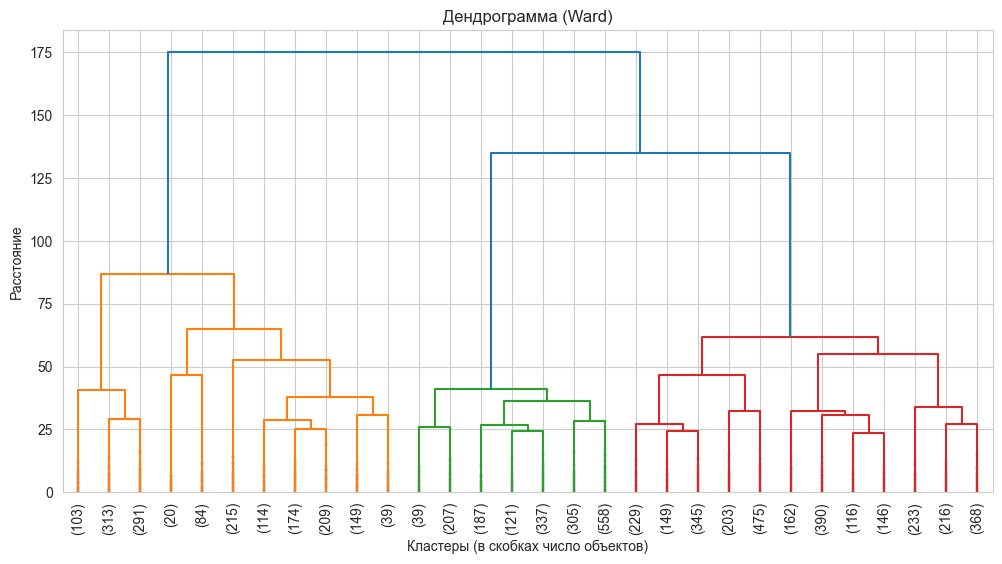

In [12]:
# Дендрограмма (метод Уорда), показаны последние 30 объединений
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, show_contracted=True)
plt.title('Дендрограмма (Ward)')
plt.xlabel('Кластеры (в скобках число объектов)')
plt.ylabel('Расстояние')
plt.show()

### Выводы (Вопрос 5)

- Агломеративная кластеризация (Ward, 2 кластера) тоже хорошо разделяет вина по цвету: 1568 из 1599 красных в одном кластере и 4755 из 4898 белых в другом. Чистота 97.3% против 98.3% у K-means, то есть результат немного хуже, но очень близок.
- Разбиения двух методов согласуются: большая часть объектов попадает в соответствующие кластеры (1612 и 4735 совпадений из 6497). Различаются порядка 150 вин. Номера кластеров между методами не совпадают (кластеру 0 K-means соответствует кластер 1 агломеративного), что нормально.
- На дендрограмме последнее объединение происходит на наибольшем расстоянии (около 175), что поддерживает деление на 2 группы. Однако предпоследнее объединение тоже высокое (около 135), поэтому 3 кластера также выглядят обоснованно, что согласуется с выводом по методу локтя.

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы quality, color и agglom. Создайте из него `X_without_kmeans`, удалив столбец kmeans.
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

In [13]:
# Бинарная цель: качество выше 7
y = (data['quality'] > 7).astype(int)
print('Доля положительного класса:', round(y.mean(), 4), '| объектов:', y.sum())

X_with_kmeans = data.drop(['quality', 'color', 'agglom'], axis=1)
X_without_kmeans = X_with_kmeans.drop('kmeans', axis=1)

sss = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=RANDOM_STATE)

def cv_rf(Xdf):
    scores = []
    for tr, te in sss.split(Xdf, y):
        rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
        rf.fit(Xdf.iloc[tr], y.iloc[tr])
        scores.append(roc_auc_score(y.iloc[te], rf.predict_proba(Xdf.iloc[te])[:, 1]))
    return np.array(scores)

s_with = cv_rf(X_with_kmeans)
s_without = cv_rf(X_without_kmeans)
print(f'С признаком kmeans:   {s_with.mean():.4f} +- {s_with.std():.4f}')
print(f'Без признака kmeans:  {s_without.mean():.4f} +- {s_without.std():.4f}')

Доля положительного класса: 0.0305 | объектов: 198
С признаком kmeans:   0.8995 +- 0.0098
Без признака kmeans:  0.9032 +- 0.0140


### Выводы (Вопрос 6, часть 1)

- Целевая переменная сильно несбалансирована: только 198 вин (3%) имеют качество выше 7, поэтому используем ROC-AUC, а не accuracy.
- Random Forest с признаком `kmeans` дал средний ROC-AUC 0.8995, без него 0.9032. Разница (около 0.004) меньше разброса между разбиениями (стандартное отклонение 0.010-0.014), то есть значимого улучшения нет.
- Причина: лес и так восстанавливает такое разбиение по цвету из исходных признаков, а бинарный признак из 2 кластеров не несет новой информации о качестве.

Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование one-hot и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.

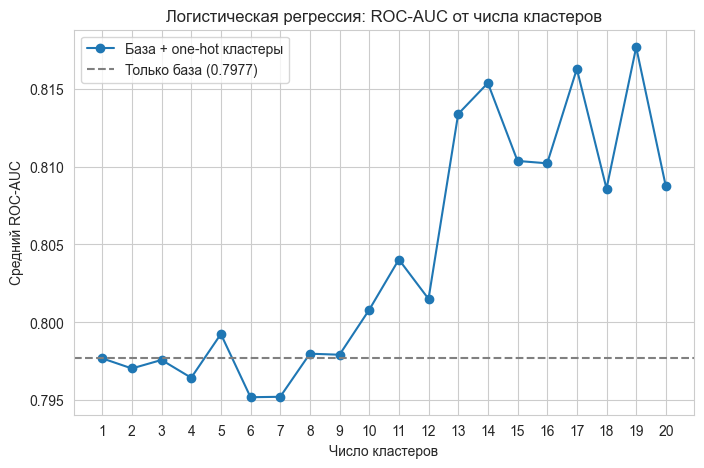

Лучшее n: 19 | ROC-AUC: 0.8177 | база: 0.7977


,roc_auc
1,0.7977
2,0.7970
3,0.7976
4,0.7965
5,0.7993
6,0.7952
7,0.7952
8,0.7980
9,0.7979
10,0.8008


In [14]:
# Влияние числа кластеров: one-hot метки k-means + логистическая регрессия
# Базовый набор: непрерывные признаки (после log1p и стандартизации, иначе логрегрессия плохо сходится)
base = X_scaled[float_columns]

def cv_lr(Xdf):
    scores = []
    for tr, te in sss.split(Xdf, y):
        lr = LogisticRegression(max_iter=2000)
        lr.fit(Xdf.iloc[tr], y.iloc[tr])
        scores.append(roc_auc_score(y.iloc[te], lr.predict_proba(Xdf.iloc[te])[:, 1]))
    return np.mean(scores)

lr_scores = []
for n in range(1, 21):
    labels = KMeans(n_clusters=n, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    onehot = pd.get_dummies(labels, prefix='km').astype(float)
    onehot.index = base.index
    lr_scores.append(cv_lr(pd.concat([base, onehot], axis=1)))

baseline_lr = cv_lr(base)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), lr_scores, 'o-', label='База + one-hot кластеры')
plt.axhline(baseline_lr, color='gray', ls='--', label=f'Только база ({baseline_lr:.4f})')
plt.xticks(range(1, 21))
plt.xlabel('Число кластеров')
plt.ylabel('Средний ROC-AUC')
plt.legend()
plt.title('Логистическая регрессия: ROC-AUC от числа кластеров')
plt.show()
print('Лучшее n:', int(np.argmax(lr_scores)) + 1, '| ROC-AUC:', round(max(lr_scores), 4), '| база:', round(baseline_lr, 4))
pd.Series(lr_scores, index=range(1, 21), name='roc_auc').round(4).to_frame()

### Выводы (Вопрос 6, часть 2)

- Для логистической регрессии признаки-кластеры дают эффект: базовый ROC-AUC 0.7977, при добавлении one-hot кластеров он растет до 0.81-0.82 при 13-20 кластерах (максимум 0.8177 при n=19).
- При малом числе кластеров (1-9) улучшения нет: ROC-AUC колеблется около базового значения. Линейная модель получает выигрыш, когда кластеры достаточно мелкие и кодируют нелинейные локальные структуры данных.
- Рост небольшой (около 2 пунктов) и немонотонный, а результаты при n=13-20 различаются в пределах шума, поэтому конкретное лучшее n (19) не стоит считать надежным оптимумом.
- Итог: кластеризация как инженерия признаков полезна для линейных моделей и малополезна для ансамблей деревьев, которые сами строят нелинейные границы.